In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow import keras
from tensorflow.keras.layers import Dense, Flatten, Reshape, Input, Layer, BatchNormalization, Dropout

In [4]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# стандартизация входных данных
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

x_train = np.reshape(x_train, (len(x_train), 28, 28, 1))
x_test  = np.reshape(x_test,  (len(x_test),  28, 28, 1))

In [5]:
hidden_dim = 2
batch_size = 60 # должно быть кратно 60 000

def dropout_and_batch(x):
    return Dropout(0.3)(BatchNormalization()(x))

input_img = Input((28, 28, 1))
x = Flatten()(input_img)
x = Dense(256, activation='relu')(x)
x = dropout_and_batch(x)
x = Dense(128, activation='relu')(x)
x = dropout_and_batch(x)

z_mean = Dense(hidden_dim)(x)
z_log_var = Dense(hidden_dim)(x)

def noiser(args):
    mean, log_var = args
    # batch ölçüsü sabit yazılmır, dinamik götürülür
    N = tf.random.normal(shape=tf.shape(mean), mean=0., stddev=1.0)
    return tf.exp(log_var / 2) * N + mean

class Sampler(Layer):
    # Keras 3-də KerasTensor-ları tf funksiyalarına birbaşa vermək olmur,
    # ona görə sampling və KL loss layer daxilində hesablanır
    def call(self, inputs):
        mean, log_var = inputs
        kl_loss = -0.5 * tf.reduce_sum(1 + log_var - tf.square(mean) - tf.exp(log_var), axis=-1)
        self.add_loss(tf.reduce_mean(kl_loss))
        return noiser(inputs)

    def compute_output_shape(self, input_shape):
        return input_shape[0]

h = Sampler()([z_mean, z_log_var])

input_dec = Input(shape=(hidden_dim,))
d = Dense(128, activation='relu')(input_dec)
d = dropout_and_batch(d)
d = Dense(256, activation='relu')(d)
d = dropout_and_batch(d)
d = Dense(28*28, activation='sigmoid')(d)
decoded = Reshape((28, 28, 1))(d)

encoder = keras.Model(input_img, h, name='encoder')
decoder = keras.Model(input_dec, decoded, name='decoder')
vae = keras.Model(input_img, decoder(encoder(input_img)), name="vae")

In [6]:
def vae_loss(x, y):
    x = tf.reshape(x, (-1, 28*28))
    y = tf.reshape(y, (-1, 28*28))
    loss = tf.reduce_sum(tf.square(x - y), axis=-1)
    return loss  # KL loss Sampler layer-in içində əlavə olunur

vae.compile(optimizer='adam', loss=vae_loss)

In [7]:
vae.fit(x_train, x_train, epochs=5, batch_size=batch_size, shuffle=True)

Epoch 1/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - loss: 68.5597
Epoch 2/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 13s 13ms/step - loss: 47.5256
Epoch 3/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 19s 19ms/step - loss: 45.1606
Epoch 4/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - loss: 44.1301
Epoch 5/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - loss: 43.5191


100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


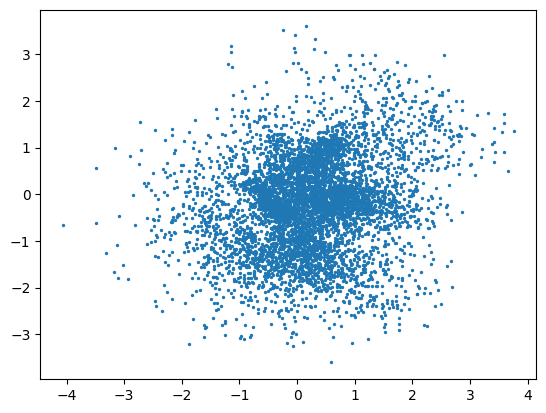

In [8]:
h = encoder.predict(x_test[:6000], batch_size=batch_size)
plt.scatter(h[:, 0], h[:, 1], s=2)
plt.show()

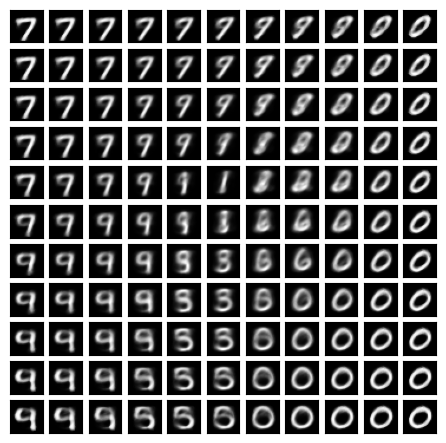

In [15]:
n = 5
total = 2*n+1

plt.figure(figsize=(total/2, total/2))

num = 1
for i in range(-n, n+1):
    for j in range(-n, n+1):
        ax = plt.subplot(total, total, num)
        num += 1
        img = decoder.predict(np.expand_dims([3*i/n, 3*j/n], axis=0), verbose=0)
        plt.imshow(img.squeeze(), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

plt.show()